# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-03-15 07:43:14,923:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-15 07:43:14,923 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-15 07:43:15,189 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux

from skewerjax.optical_depth import line_profile
import skewerjax.optical_depth.optical_depth as od
import skewerjax.optical_depth.analytic_solutions as analytic_solutions

from skewerjax.constants.physical_constants import phys
from skewerjax.optical_depth.voigt import Gaussian

# Auxiliary objects that would be employed throughout the notebook

### Define radiation domination cosmology to employ in the different examples that require it

In [3]:
# Create cosmology object
cosmology = Cosmology(
    H0=phys.H0,
    Omega_r_0=1.0,  # Radiation density (CMB + neutrinos)
    Omega_m_0=0.0,
    Omega_k_0=0.0,
    Omega_lambda_0=0.0,
)

# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time

ii_cosmology = 0

### Define wavelength range and lines to study

In [4]:
wavelengths = jnp.linspace(970, 1230, 2**16)  # in Angstroms

line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])
line_bundle_null = sjx.constants.lines.LineBundle(["nullHI-LyA", "nullHI-LyB", "nullSiIII1206"])

### Auxiliary variables

In [5]:
T0_tiny = jnp.finfo(jnp.dtype('float32')).tiny

T0_min = 1e4
T0_max = 1e8

n0_min = 1e-9
n0_max = 1e-3
n0_ref = 1e-7

L_box_Kpc      = 1e-3 # in Mpc
L_box_five_Mpc = 5    # in Mpc

# Validation with $T=0,\, v_{LoS}=0, \, n=n_0, a(x) = 1.0, a_0 = 1.0$

In [6]:
# Define the fields to sample

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_Kpc)),     # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min, n0_max, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_Kpc)),     # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min, n0_max, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    }
})

# Define skewers

N_sk = 7
N_ppsk = 32

_points        = aux.make_plane_points(L_box_Kpc, 'x', L_box_Kpc/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]), # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
)

# Compute optical depth

optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields)
F_over_F0 = jnp.exp(-optical_depth)

2026-03-15 07:43:15,811 - INFO - Initializing SkewerBundle with 7 skewers, 32 points per skewer
2026-03-15 07:43:15,873 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 7 skewers
2026-03-15 07:43:15,895 - INFO - All skewers set to absorption mode
2026-03-15 07:43:15,968 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-03-15 07:43:16,268 - INFO - Computing comoving distances along skewer direction
2026-03-15 07:43:16,462 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-03-15 07:43:16,463 - INFO - Storing quadri-vectors
2026-03-15 07:43:16,506 - INFO - SkewerBundle initialization complete
2026-03-15 07:43:16,507 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-03-15 07:43:16,507 - INFO - [OPTICAL_DEPTH] Extracting 7 skewers with 32 points each
2026-03-15 07:43:16,551 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species
2026-03-15 07:43:17,930 - INF

### Analytic benchmark

\begin{align}
\tau_j(\lambda,x_{\rm f},x_{\rm em})
=
\frac{\mathcal{C}_j\, n_0}{a_0^2}
\left(x_{\mathrm{f}} - x_{\mathrm{em}}\right)
L \left( c \left(\frac{1}{\lambda_j} - \frac{a_0}{\lambda} \right) ;\; \gamma_j  \right)
.\quad\quad
\gamma_j = \frac{A_j}{4\pi}
\end{align}

In [7]:
# Extract the value of the number densities for each skewer (shared for the different lines)
quadri_vectors_analytic = jnp.array([
    jnp.ones(N_sk) * skewer_bundle.a0[0],
    jnp.ones(N_sk) * L_box_Kpc / 2,
    jnp.linspace(0, L_box_Kpc, N_sk),
    jnp.ones(N_sk) * L_box_Kpc / 2,    
]).T
indices_for_species = {
    sp: line_bundle.indices_for_species(sp) for sp in line_bundle.species_keys
}
sampled_number_densities_cm3 = fields.tile_field_to_lines(
    "number_density",
    quadri_vectors_analytic,
    indices_for_species=indices_for_species,
)[0]

In [8]:
optical_depth_analytic = analytic_solutions.compute_optical_depth_analytical_static_Natural(
    wavelengths, line_bundle.lambda0_A, line_bundle.A21_GHz, line_bundle.f_osc,
    skewer_bundle.a0,
    L_box_Kpc * jnp.ones(len(skewer_bundle.a0)),
    sampled_number_densities_cm3
)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_578144/2058523373.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


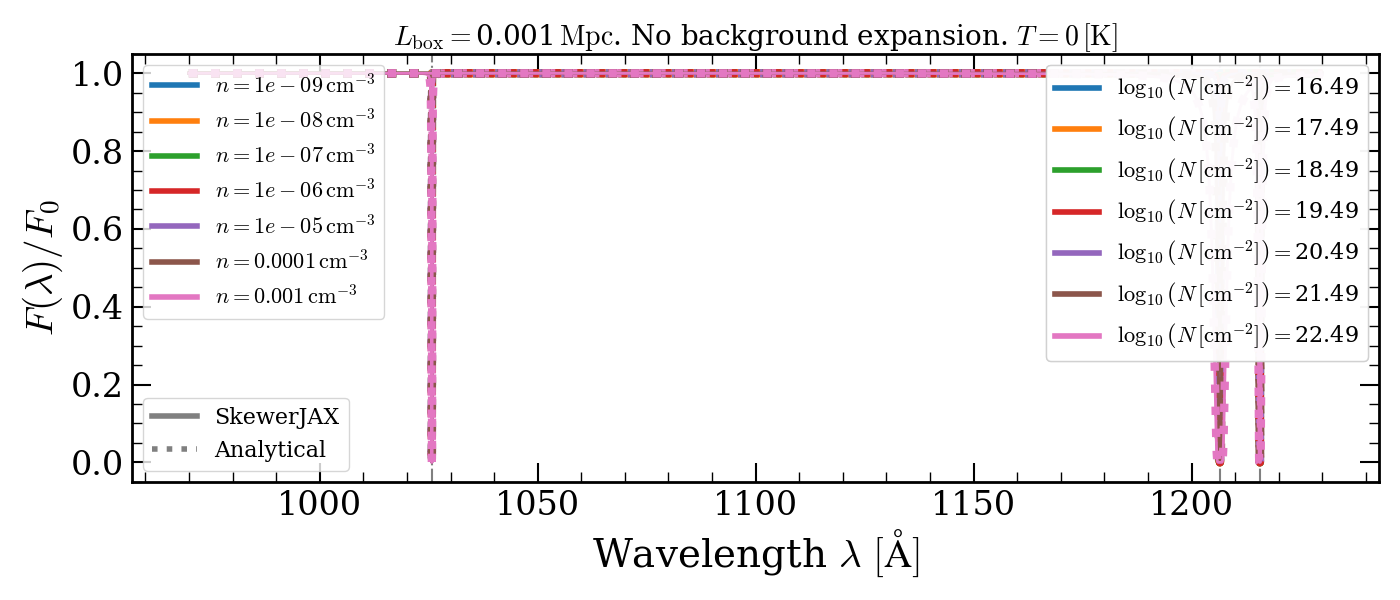

/home/dlopez/tmp/pip-tmp/ipykernel_578144/2058523373.py:78: RuntimeWarning: invalid value encountered in divide
  residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1


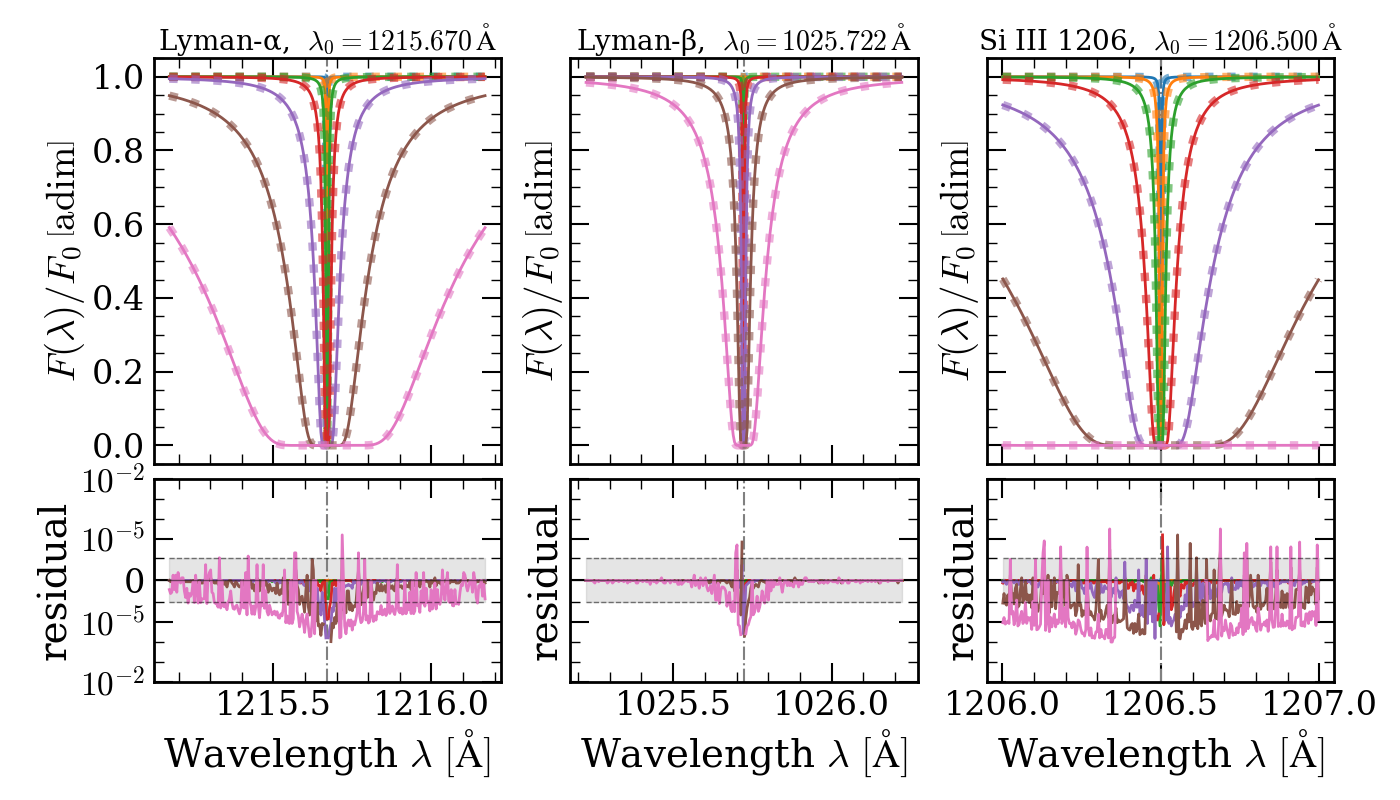

In [9]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)           # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                           # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)            # (N_sp, N_sk, N_lambda)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
for i_sp, line in enumerate(line_bundle.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=6.0)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(r"$L_{\mathrm{box}} = $" + str(L_box_Kpc) + r"$\,\mathrm{Mpc}$" + ". No background expansion. " + r"$T = 0 \,[\mathrm{K}]$", fontsize=20)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical')
]
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles_n = []
handles_N = []
for i_sk in range(N_sk):
    _sampled_numbr_density_cm3 = sampled_number_densities_cm3[i_sk]
    _lbl = rf"$n = {_sampled_numbr_density_cm3:.2g} \, \mathrm{{cm^{{-3}}}}$"
    handles_n.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

    _quantity = jnp.log10(_sampled_numbr_density_cm3 * 1e6 * L_box_Kpc * phys.Mpc_to_m)
    _lbl = r"$\log_{{10}} \left(N\, [\mathrm{{cm^{{-2}}}}] \right) =$" + str(round(_quantity, 2))
    handles_N.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

leg = ax.legend(handles=handles_n, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(leg)
leg = ax.legend(handles=handles_N, loc="upper right", fontsize=16, ncols=1)
ax.add_artist(leg)

fig.tight_layout()
plt.show()




# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 0.5   # adjust to taste
N_lines = line_bundle.n_lines
fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, 
    figsize=(14, 8), 
    sharex='col',
    sharey='row',
    gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):
    lambda0 = line.lambda0_A
    
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]

    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=6.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1
        ax_res.plot(lam_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("residual")
    ax_res.set_yscale("symlog", linthresh=1e-6)
    
    major_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
    ax_res.set_yticks(major_ticks)
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)

plt.show()

# Validation with $A_{j} = 0,\, v_{LoS}=0, \, n=n_0, T = T_0, a(x) = 1.0, a_0 = 1.0$

In [10]:
# Define the fields to sample

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_Kpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_Kpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    }
})

# Define skewers

N_sk = 5
N_ppsk = 32

_points        = aux.make_plane_points(L_box_Kpc, 'y', L_box_Kpc/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]),   # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
)

# Compute optical depth

optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle_null, fields)
F_over_F0 = jnp.exp(-optical_depth)

2026-03-15 07:43:21,631 - INFO - Initializing SkewerBundle with 5 skewers, 32 points per skewer
2026-03-15 07:43:21,650 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 5 skewers
2026-03-15 07:43:21,668 - INFO - All skewers set to absorption mode
2026-03-15 07:43:21,740 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-03-15 07:43:22,014 - INFO - Computing comoving distances along skewer direction
2026-03-15 07:43:22,205 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-03-15 07:43:22,205 - INFO - Storing quadri-vectors
2026-03-15 07:43:22,252 - INFO - SkewerBundle initialization complete
2026-03-15 07:43:22,252 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-03-15 07:43:22,253 - INFO - [OPTICAL_DEPTH] Extracting 5 skewers with 32 points each
2026-03-15 07:43:22,298 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species
2026-03-15 07:43:23,425 - INF

### Analytic benchmark

\begin{align}
\tau_j(\lambda,x_{\rm f},x_{\rm em})
=
\frac{\mathcal{C}_j\, n_0}{a_0^2}
\left(x_{\mathrm{f}} - x_{\mathrm{em}}\right)
G \left( c \left(\frac{1}{\lambda_j} - \frac{a_0}{\lambda} \right) ;\; \sigma_j  \right)
.\quad\quad
\sigma_j = \frac{1}{2\lambda_j}\sqrt{\frac{2 k T_{j, 0}}{m_j}}
\end{align}

In [11]:
sampled_temperatures_K = fields.temperature(skewer_bundle.quadri_vectors[ii_cosmology])[0, :, 0]

In [12]:
optical_depth_analytic = analytic_solutions.compute_optical_depth_analytical_static_Thermal(
    wavelengths, line_bundle.lambda0_A, line_bundle.mass_amu, line_bundle.f_osc,
    skewer_bundle.a0,
    L_box_Kpc * jnp.ones(len(skewer_bundle.a0)),
    n0_ref * jnp.ones(len(skewer_bundle.a0)),
    sampled_temperatures_K
)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_578144/1957874243.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


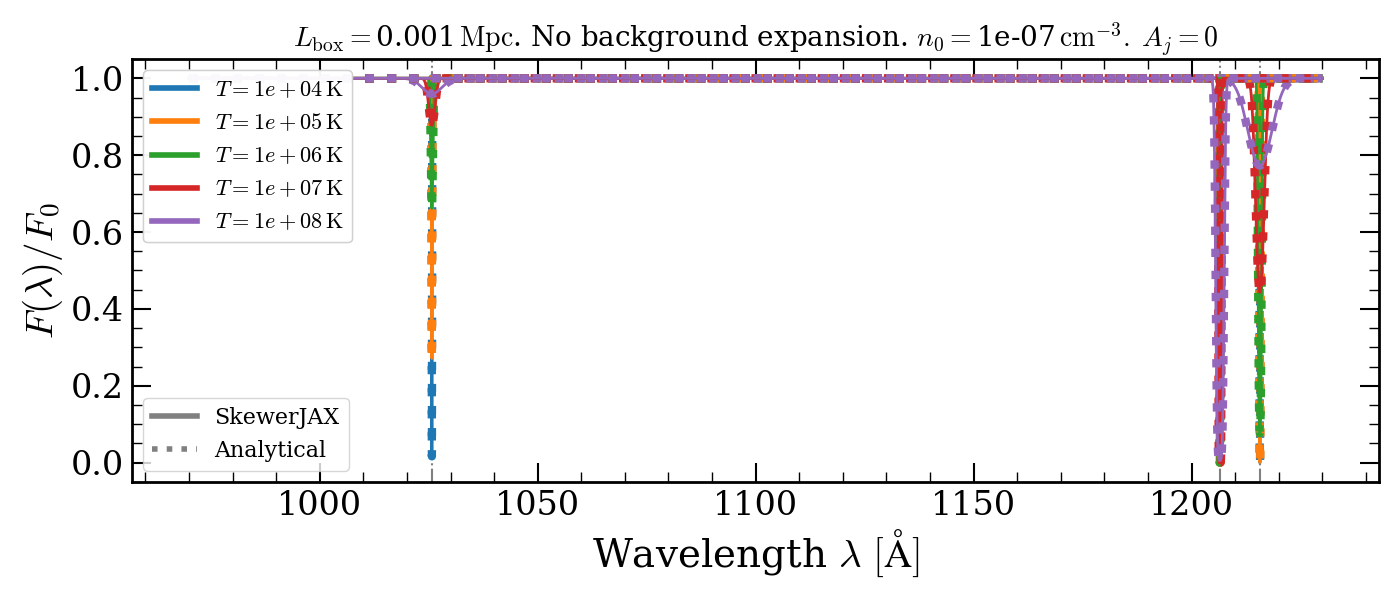

/home/dlopez/tmp/pip-tmp/ipykernel_578144/1957874243.py:74: RuntimeWarning: invalid value encountered in divide
  residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1


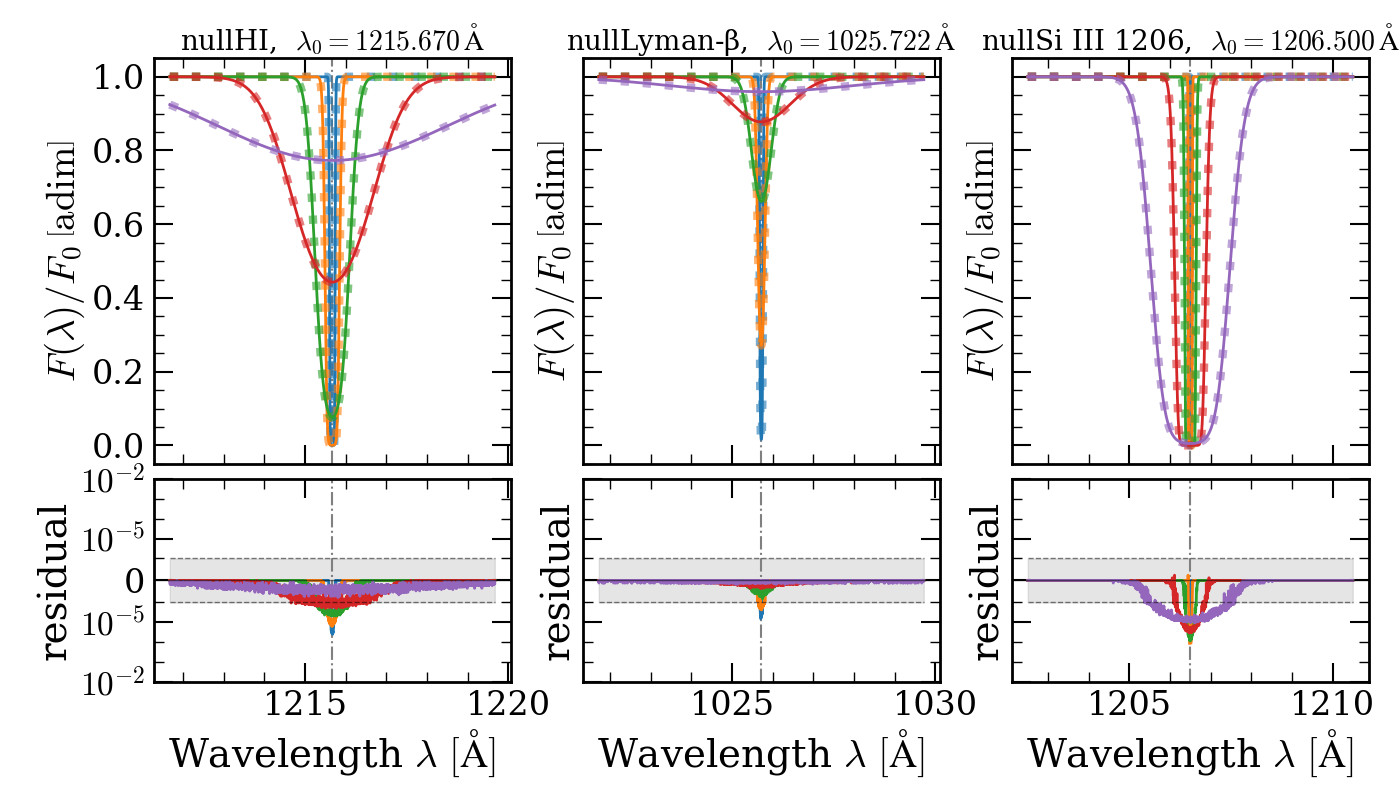

In [13]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)           # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                           # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)            # (N_sp, N_sk, N_lambda)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
for i_sp, line in enumerate(line_bundle_null.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=6.0)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(
    r"$L_{\mathrm{box}} = $" + str(L_box_Kpc) + r"$\,\mathrm{Mpc}$" + ". No background expansion. " + r"$n_0 = $" + str(n0_ref) + r"$ \, \mathrm{cm^{-3}}.\;$" + r"$A_j = 0$",
    fontsize=20
)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical')
]
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = []
for i_sk in range(N_sk):
    _sampled_T_K = sampled_temperatures_K[i_sk]
    _lbl = rf"$T = {_sampled_T_K:.2g} \, \mathrm{{K}}$"
    handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

leg = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(leg)

fig.tight_layout()
plt.show()




# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 4.0   # adjust to taste
N_lines = line_bundle_null.n_lines
fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, 
    figsize=(14, 8), 
    sharex='col',
    sharey='row',
    gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle_null.lines)):
    lambda0 = line.lambda0_A
    
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]

    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=6.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1
        ax_res.plot(lam_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("residual")
    ax_res.set_yscale("symlog", linthresh=1e-6)
    
    major_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
    ax_res.set_yticks(major_ticks)
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)

plt.show()

# Numerical VS Analytical for a rad.-domination with $n=n_0, T=0$

In [14]:
# Define fields

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_five_Mpc)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                 # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),     # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                       # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_five_Mpc)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                 # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),     # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                       # UNITS: [GHz]
    }
})

# Define skewers
# create a skewer that go from x=0 to x=L_box with y=L_box/2 and z=L_box/2

N_sk = 2
N_ppsk = 128

_points = jnp.array([
    jnp.linspace(0.0, L_box_five_Mpc, N_ppsk),
    L_box_five_Mpc/2 * jnp.ones(N_ppsk),
    L_box_five_Mpc/2 * jnp.ones(N_ppsk)
]).T

_points = jnp.tile(_points[None, ...], (N_sk, 1, 1))

skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=[1.0, 0.99999976],                                         # scale factor at which ICs are defined
    x0=[0.0, 0.0],                                                # comoving distance at which ICs are defined, default: 0.0
    ICs_defined_at_index=[-1, 0],                                 # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption=["absorption", "emission"],     # whether the ICs are defined at emission or absorption, default: 'absorption'
    cosmologies=cosmology                                         # when manual_scale_factors are not provided, cosmologies must be defined
)

# Compute optical depth

optical_depth = od.compute_optical_depth(skewer_bundle,wavelengths, line_bundle, fields)
F_over_F0 = jnp.exp(-optical_depth)

2026-03-15 07:43:26,322 - INFO - Initializing SkewerBundle with 2 skewers, 128 points per skewer
2026-03-15 07:43:26,386 - INFO - Using per-skewer ICs_defined_at_index: [-1  0]
2026-03-15 07:43:26,387 - INFO - Using per-skewer emission/absorption flags
2026-03-15 07:43:26,456 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-03-15 07:43:26,732 - INFO - Computing comoving distances along skewer direction
2026-03-15 07:43:26,921 - INFO - Computing scale factors from cosmology
2026-03-15 07:43:27,953 - INFO - Storing quadri-vectors
2026-03-15 07:43:28,000 - INFO - SkewerBundle initialization complete
2026-03-15 07:43:28,000 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-03-15 07:43:28,000 - INFO - [OPTICAL_DEPTH] Extracting 2 skewers with 128 points each
2026-03-15 07:43:28,046 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species
2026-03-15 07:43:29,179 - INFO - [OPTICAL_DEPTH] Lin

### Analytic benchmark

\begin{align}
\tau_j(\lambda,x_{\rm f},x_{\rm em}, x_\mathrm{obs})
=
\frac{n_0 \lambda\mathcal{C}_j}{\pi a(x_\mathrm{obs}) H_0}
\left.
\arctan\left\lbrace
\frac{c}{\gamma_j}
\left(
\frac{1}{\lambda_j} -
\frac{1}{
\frac{\lambda}{a(x_\mathrm{obs})}
\left[
\frac{H_0}{c}
\left(x - x_0\right) + a_0
\right]
}
\right)
\right\rbrace
\right|_{x_{\rm em}}^{x_f}
\end{align}

In [15]:
xem_Mpc = jnp.array([-L_box_five_Mpc, 0.])
xf_Mpc  = jnp.array([0., L_box_five_Mpc])

optical_depth_analytic = analytic_solutions.compute_optical_depth_analytical_radiation_domination_Natural(
    wavelengths,
    line_bundle.lambda0_A,
    line_bundle.A21_GHz,
    line_bundle.f_osc,
    skewer_bundle.a0,
    skewer_bundle.x0,
    xem_Mpc=xem_Mpc,
    xf_Mpc=xf_Mpc,
    n0_cm3=jnp.array([n0_ref, n0_ref])
)

F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_578144/369379309.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


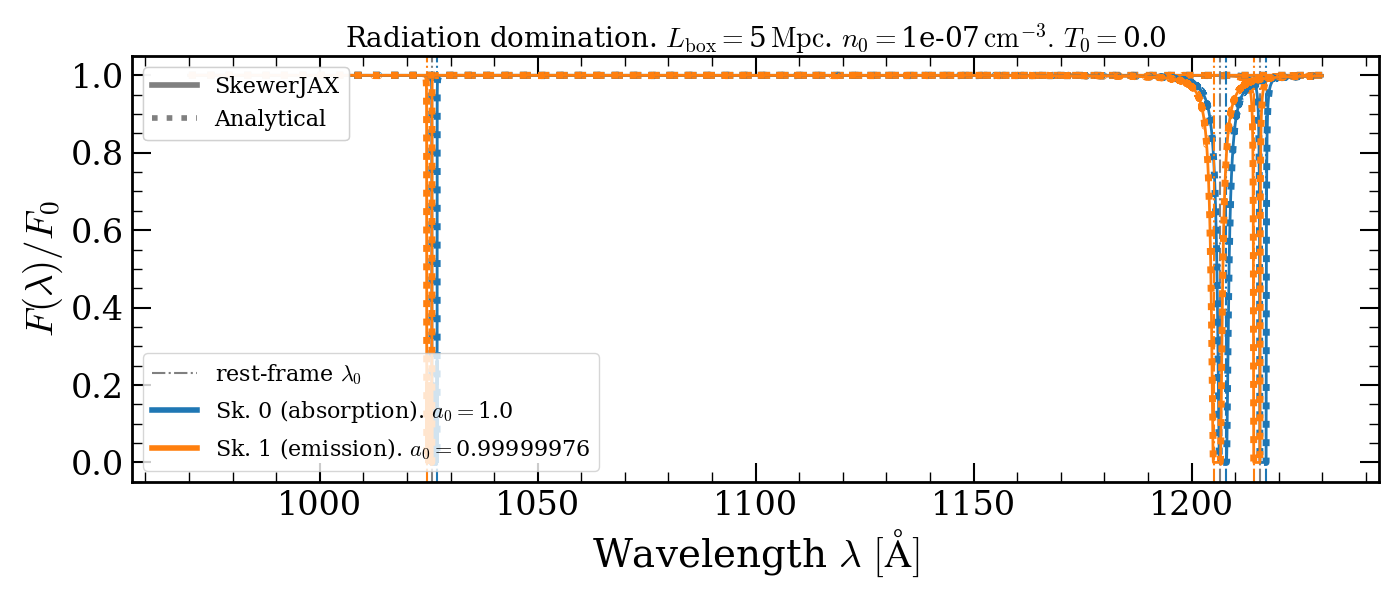

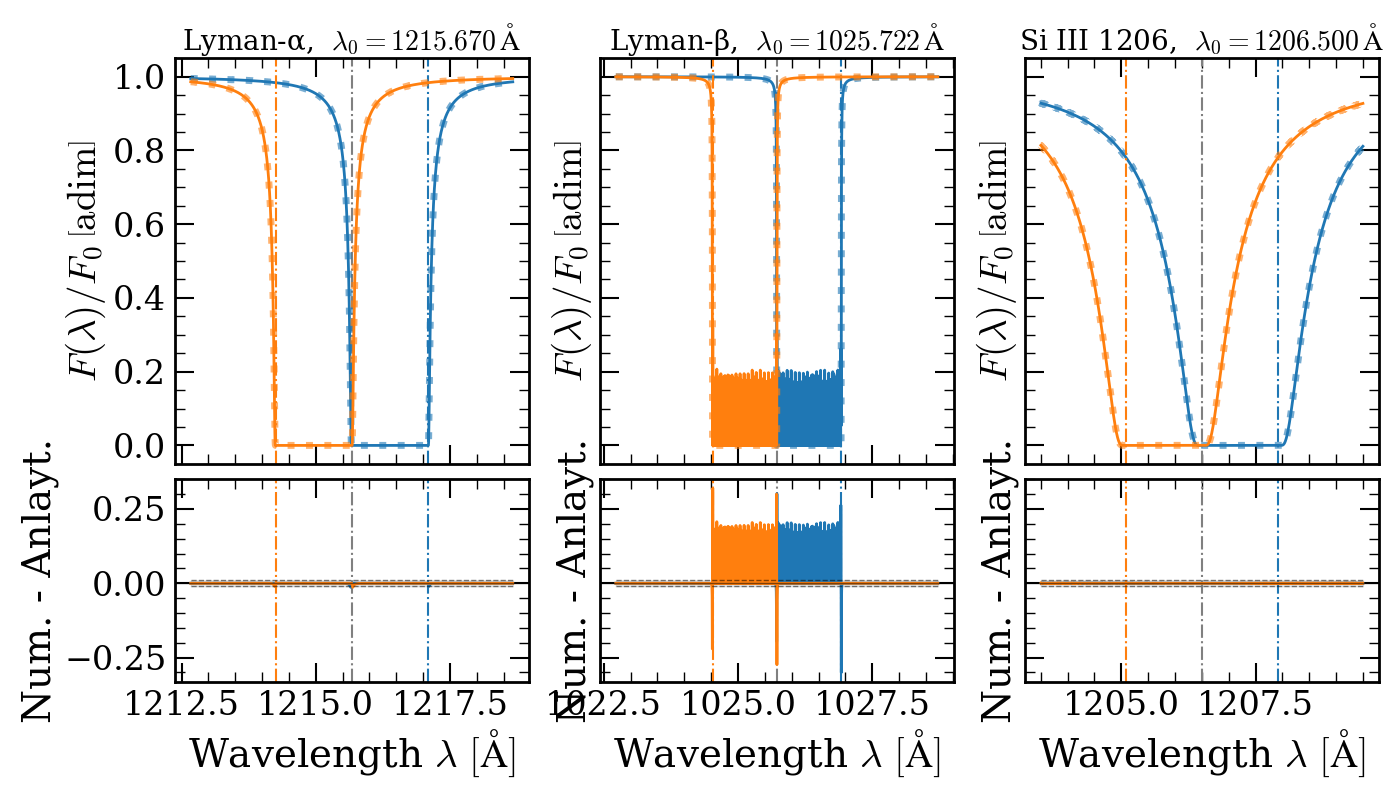

In [16]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)                             # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                             # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)              # (N_sp, N_sk, N_lambda)

_indicies_final_array = jnp.where(skewer_bundle.ICs_defined_at_index == 0, -1, 0)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
handles = [Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'rest-frame $\lambda_0$'),]
for i_sp, line in enumerate(line_bundle.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=5.0)

        _emission_or_absorption = "absorption" if skewer_bundle.is_absorption[i_sk] else "emission"
        if i_sp == 0:
            handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle='-',
                label="Sk. " + str(i_sk) + " (" + _emission_or_absorption + r"). $a_0 = $" + str(skewer_bundle.a0[i_sk]) )
            )
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical')
]
legend = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(legend)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(r"Radiation domination. $L_{\mathrm{box}} = $" + str(L_box_five_Mpc) + r"$\,\mathrm{Mpc}$. $n_0 = $" + str(n0_ref) + r"$\,\mathrm{cm}^{-3}.\, T_0 = $" + str(round(T0_tiny, 4)), fontsize=20)

fig.tight_layout()
plt.show()



# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 3.0   # adjust to taste
N_lines = line_bundle.n_lines

fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, figsize=(14, 8), sharex='col', sharey='row', gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)


for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):
    lambda0 = line.lambda0_A
  
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]
    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax_main.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)
        ax_res.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=5.0, alpha=0.6)

        # Compute residual
        residual = F_over_F0_np[i_sp, i_sk, mask] - F_over_F0_analytic[i_sp, i_sk, mask]
        ax_res.plot(lam_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-2, 1e-2, color="grey", alpha=0.2)
    ax_res.hlines(1e-2, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-2, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
  
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("Num. - Anlayt.")
    # ax_res.set_yscale("symlog", linthresh=1e-1)
  
    # major_ticks = [-1e-1, -1e-5, 0.0, 1e-5, 1e-1]
    # ax_res.set_yticks(major_ticks)
    # ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    # ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()

# Numerical VS Analytical for a rad.-domination with $n=n_0,\, A_{21} = 0, T=T_0$

### Define fields

In [17]:
n0_ref = 5e-11

T0_min = 5e4
T0_max = 5e6


fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_five_Mpc)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),               # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),   # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                       # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                     # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_five_Mpc)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),               # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),   # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                       # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                     # UNITS: [GHz]
    },
})

### Define skewers

In [18]:
N_sk = 2
N_ppsk = 42

_points        = aux.make_plane_points(L_box_five_Mpc, 'y', L_box_five_Mpc/2, N_sk, N_ppsk)

In [19]:
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=[1.0, 0.99999976],                                         # scale factor at which ICs are defined
    x0=[0.0, 0.0],                                                # comoving distance at which ICs are defined, default: 0.0
    ICs_defined_at_index=[-1, 0],                                 # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption=["absorption", "emission"],     # whether the ICs are defined at emission or absorption, default: 'absorption'
    cosmologies=cosmology                                         # when manual_scale_factors are not provided, cosmologies must be defined
)

2026-03-15 07:43:32,243 - INFO - Initializing SkewerBundle with 2 skewers, 42 points per skewer
2026-03-15 07:43:32,245 - INFO - Using per-skewer ICs_defined_at_index: [-1  0]
2026-03-15 07:43:32,245 - INFO - Using per-skewer emission/absorption flags
2026-03-15 07:43:32,245 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-03-15 07:43:32,458 - INFO - Computing comoving distances along skewer direction
2026-03-15 07:43:32,622 - INFO - Computing scale factors from cosmology
2026-03-15 07:43:33,534 - INFO - Storing quadri-vectors
2026-03-15 07:43:33,584 - INFO - SkewerBundle initialization complete


### Compute optical depth

In [20]:
optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle_null, fields)
F_over_F0 = jnp.exp(-optical_depth)

2026-03-15 07:43:33,922 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-03-15 07:43:33,922 - INFO - [OPTICAL_DEPTH] Extracting 2 skewers with 42 points each
2026-03-15 07:43:33,965 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species
2026-03-15 07:43:35,139 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (3, 2, 42, 65536)
2026-03-15 07:43:35,140 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-03-15 07:43:35,305 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (3, 2, 42)
2026-03-15 07:43:35,305 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-03-15 07:43:35,452 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (3, 2, 42, 65536)
2026-03-15 07:43:35,452 - INFO - [OPTICAL_DEPTH] Reorienting 2 skewers based on photon path direction mask
2026-03-15 07:43:35,577 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (2, 42, 4), dtau_dx_m (3, 2

### Analytic benchmark

\begin{align}
\tau_j(\lambda,x_{\rm f},x_{\rm em}, x_\mathrm{obs})
=
\frac{n_0 \lambda \mathcal{C}_j}{2 a(x_\mathrm{obs}) H_0}\;
\left.
\mathrm{erf}
\left\lbrace
\frac{c}{\sigma_j\sqrt{2}}\left(
\frac{1}{\lambda_j}
-
\frac{1}{\frac{\lambda}{a(x_\mathrm{obs})}
\left[
\frac{H_0}{c}\left(x - x_0\right) + a_0
\right]
}
\right)
\right\rbrace
\right|_{x_{\rm em}}^{x_f}
\end{align}


In [21]:
xem_Mpc = jnp.array([-L_box_five_Mpc, 0.])
xf_Mpc  = jnp.array([0., L_box_five_Mpc])

_T0 = jnp.array([T0_min, T0_max])

In [22]:
optical_depth_analytic = analytic_solutions.compute_optical_depth_analytical_radiation_domination_Thermal(
    wavelengths,
    line_bundle_null.lambda0_A,
    line_bundle_null.f_osc,
    line_bundle_null.mass_amu,
    _T0,
    skewer_bundle.a0,
    skewer_bundle.x0,
    xem_Mpc=xem_Mpc,
    xf_Mpc=xf_Mpc,
    n0_cm3=jnp.array([n0_ref, n0_ref])
)

F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_578144/2684887735.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


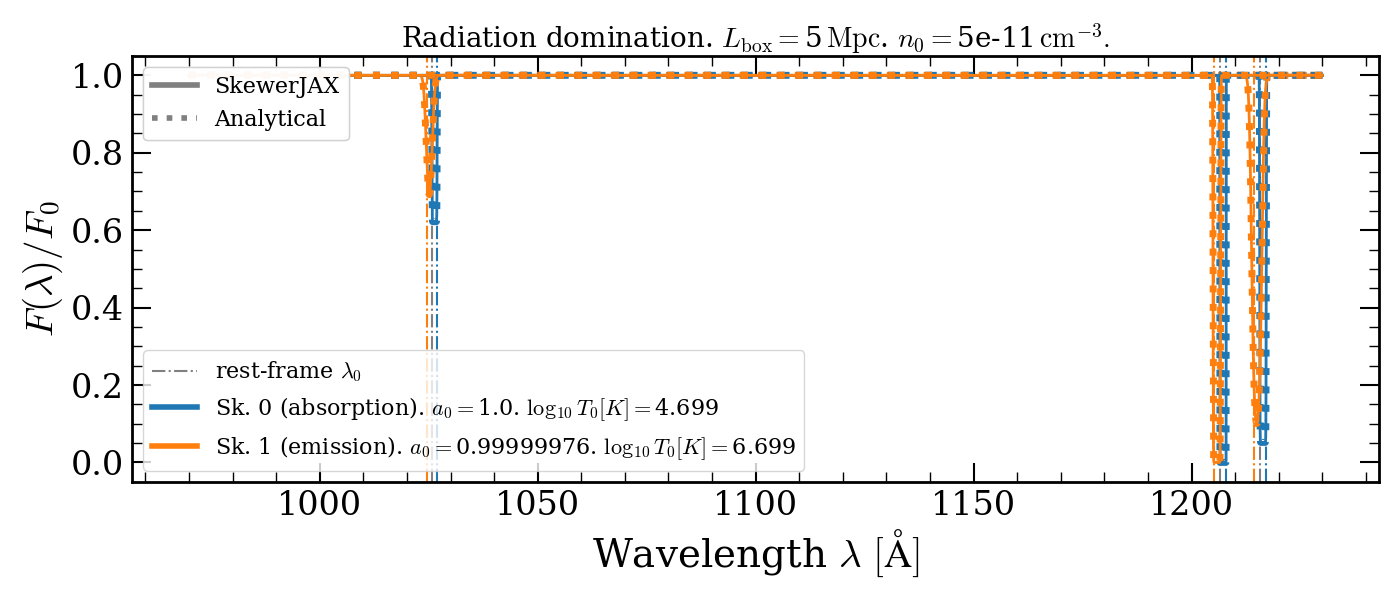

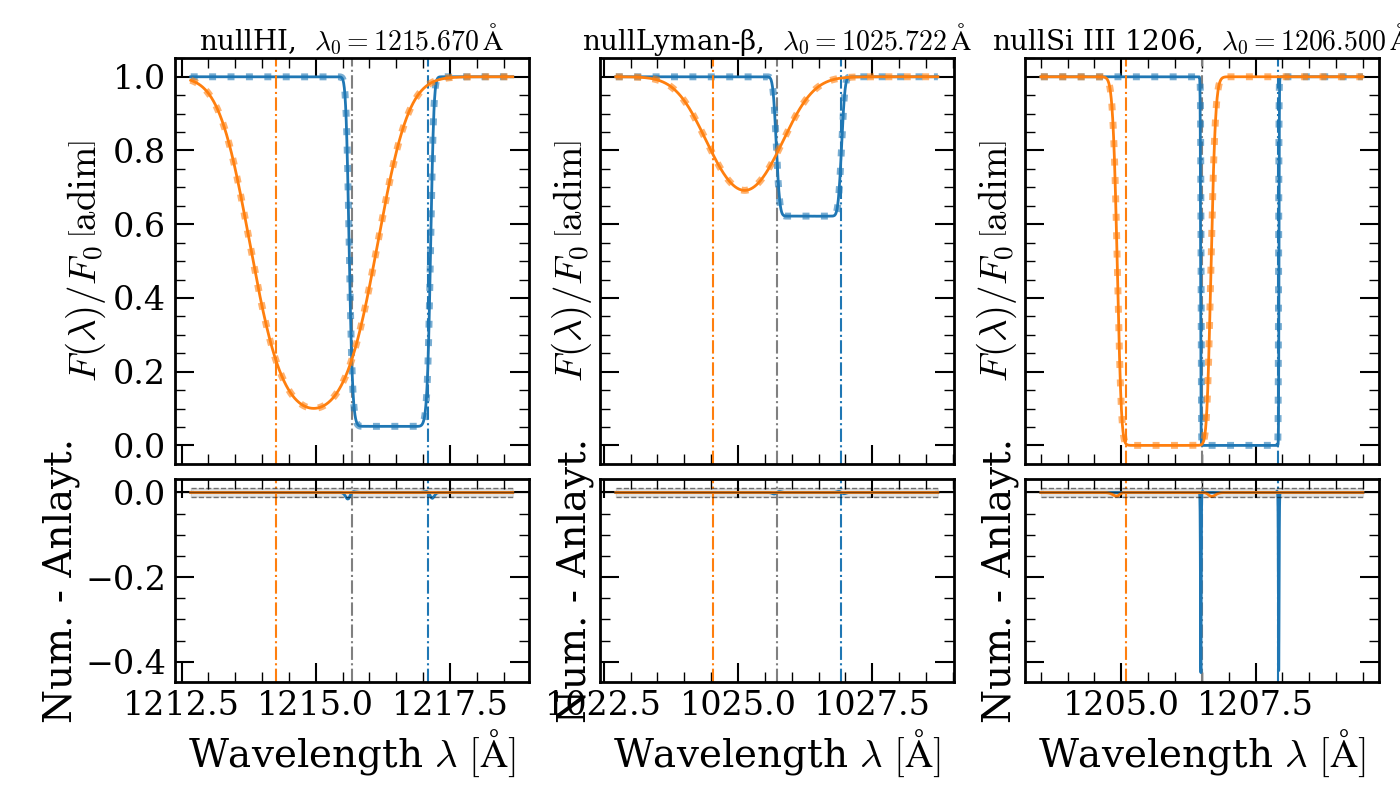

In [23]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)                             # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                             # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)              # (N_sp, N_sk, N_lambda)

_indicies_final_array = jnp.where(skewer_bundle.ICs_defined_at_index == 0, -1, 0)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
handles = [Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'rest-frame $\lambda_0$'),]
for i_sp, line in enumerate(line_bundle_null.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=5.0)

        _emission_or_absorption = "absorption" if skewer_bundle.is_absorption[i_sk] else "emission"
        if i_sp == 0:
            handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle='-',
                label="Sk. " + str(i_sk) + " (" + _emission_or_absorption + r"). $a_0 = $" + str(skewer_bundle.a0[i_sk]) + r". $\log_{10}T_0 [K]= $" + str(round(jnp.log10(_T0[i_sk]), 4)))
            )
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical')
]
legend = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(legend)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(
    r"Radiation domination. $L_{\mathrm{box}} = $" + str(L_box_five_Mpc) + r"$\,\mathrm{Mpc}$. $n_0 = $" + str(n0_ref) + r"$\,\mathrm{cm}^{-3}.$",
    fontsize=20
)

fig.tight_layout()
plt.show()



# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 3.0   # adjust to taste
N_lines = line_bundle.n_lines

fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, figsize=(14, 8), sharex='col', sharey='row', gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)


for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle_null.lines)):
    lambda0 = line.lambda0_A
  
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]
    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax_main.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)
        ax_res.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=5.0, alpha=0.6)

        # Compute residual
        residual = F_over_F0_np[i_sp, i_sk, mask] - F_over_F0_analytic[i_sp, i_sk, mask]
        ax_res.plot(lam_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-2, 1e-2, color="grey", alpha=0.2)
    ax_res.hlines(1e-2, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-2, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
  
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("Num. - Anlayt.")
    # ax_res.set_yscale("symlog", linthresh=1e-1)
  
    # major_ticks = [-1e-1, -1e-5, 0.0, 1e-5, 1e-1]
    # ax_res.set_yticks(major_ticks)
    # ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    # ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()